# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

from pathlib import Path
data_path = Path.cwd() / "unit3_ppt7_card_transactions.csv"
if not data_path.exists():
    raise FileNotFoundError(f"Missing {data_path.name}. Put the provided CSV in the same folder as this notebook.")
tx = pd.read_csv(data_path, parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

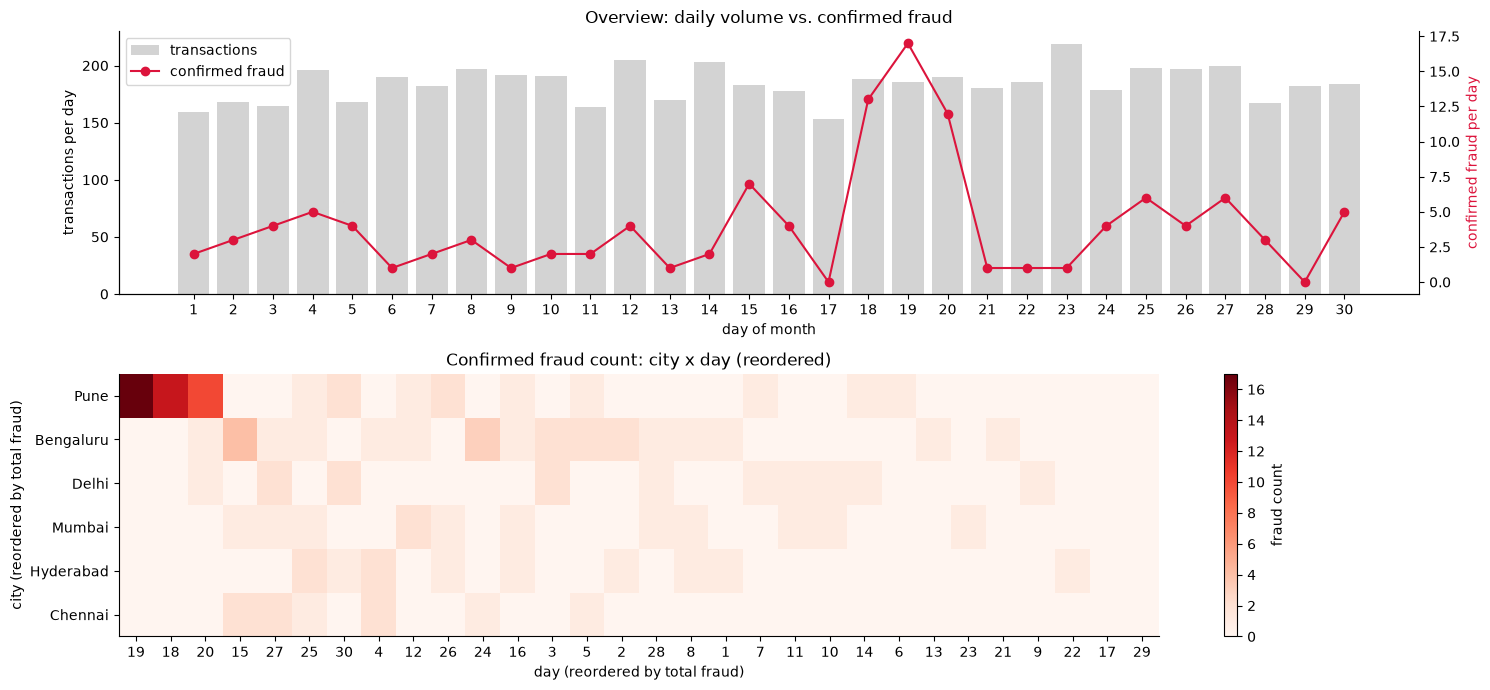

Top (city, day) cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Hyderabad  4       2
Bengaluru  2       2
Chennai    27      2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily transactions (bars) + daily confirmed fraud (line, second axis)
daily = tx.groupby("day").agg(n=("txn_id", "count"), fraud=("is_fraud", "sum"))
ax = axes[0]
ax.bar(daily.index, daily.n, color="lightgrey", label="transactions")
ax.set(xlabel="day of month", ylabel="transactions per day", title="Overview: daily volume vs. confirmed fraud")
ax.set_xticks(daily.index)
ax2 = ax.twinx()
ax2.plot(daily.index, daily.fraud, "-o", c="crimson", label="confirmed fraud")
ax2.set_ylabel("confirmed fraud per day", color="crimson")
ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

# TODO 2: city x day matrix of fraud counts, rows/columns reordered by their totals
fr = tx[tx.is_fraud == 1]
heat = (fr.pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
          .reindex(index=sorted(tx.city.unique()), columns=sorted(tx.day.unique()), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set(xlabel="day (reordered by total fraud)", ylabel="city (reordered by total fraud)",
            title="Confirmed fraud count: city x day (reordered)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3: top (city, day) cells
top = heat.stack().sort_values(ascending=False).head(8).rename("fraud_count")
print("Top (city, day) cells by confirmed fraud:")
print(top.to_string())

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

**Answer:** The overview exposed a spatio-temporal burst that an alert list sorted by score cannot show: confirmed fraud jumps from about 2–3 per day to 13, 17 and 12 on days 18–20, and the city × day matrix shows it is concentrated in Pune (17 + 13 + 10 = 40 of the 120 frauds, a third of the month). A score-sorted list shows each alert in isolation, so the cluster is just many separate rows. I found it through **overview first** (Slide 30), and the **reordered matrix** (Slide 39): sorting rows and columns by their totals pushes the Pune and days 18–20 cells together into one bright block.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

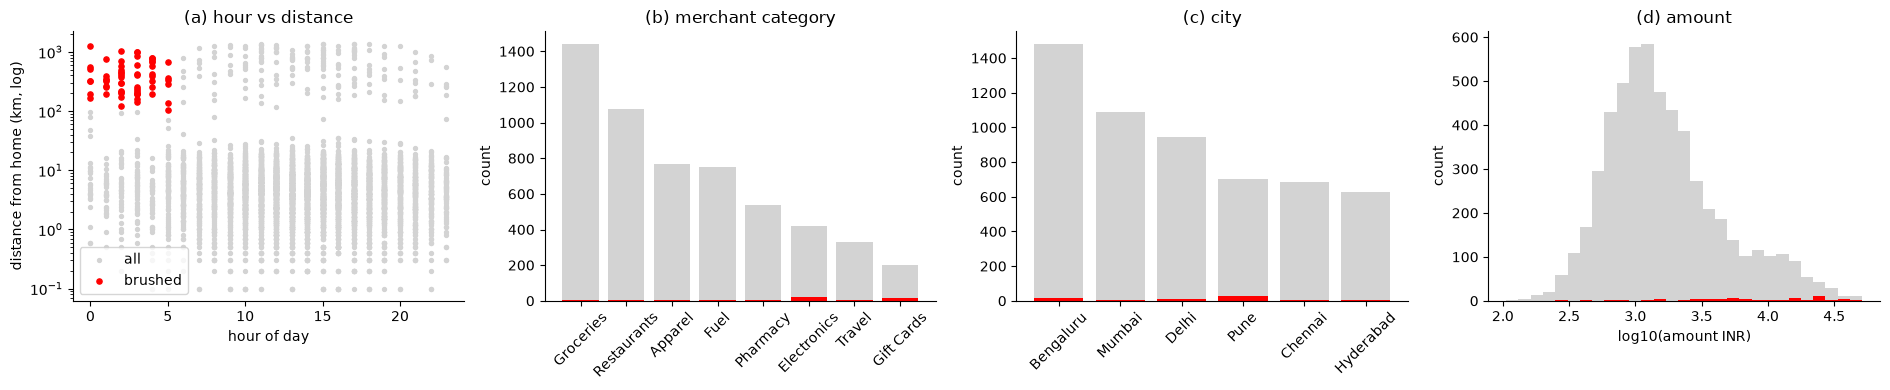

Brushed: 61 transactions (1.1% of all)
Fraud rate inside brush: 86.9% vs overall 2.2%  (40x lift)
Share of ALL fraud captured by the brush: 44.2%


In [3]:
# TODO 1: the brush = night-time AND far from home
brush = (tx.night) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2: all items grey, brushed items red
a = axes[0]
a.scatter(tx.hour, tx.distance_from_home_km, s=8, c="lightgrey", label="all")
a.scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=14, c="red", label="brushed")
a.set(yscale="log", xlabel="hour of day", ylabel="distance from home (km, log)", title="(a) hour vs distance"); a.legend()

cats = tx.merchant_category.value_counts()
cat_b = tx[brush].merchant_category.value_counts().reindex(cats.index, fill_value=0)
axes[1].bar(cats.index, cats.values, color="lightgrey"); axes[1].bar(cats.index, cat_b.values, color="red")
axes[1].set(title="(b) merchant category", ylabel="count"); axes[1].tick_params(axis="x", rotation=45)

cities = tx.city.value_counts()
city_b = tx[brush].city.value_counts().reindex(cities.index, fill_value=0)
axes[2].bar(cities.index, cities.values, color="lightgrey"); axes[2].bar(cities.index, city_b.values, color="red")
axes[2].set(title="(c) city", ylabel="count"); axes[2].tick_params(axis="x", rotation=45)

bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="red")
axes[3].set(title="(d) amount", xlabel="log10(amount INR)", ylabel="count")

plt.tight_layout(); plt.show()

# TODO 3: brush statistics
n_brush = int(brush.sum())
rate_in, rate_all = tx[brush].is_fraud.mean(), tx.is_fraud.mean()
capture = tx[brush].is_fraud.sum() / tx.is_fraud.sum()
print(f"Brushed: {n_brush} transactions ({n_brush/len(tx):.1%} of all)")
print(f"Fraud rate inside brush: {rate_in:.1%} vs overall {rate_all:.1%}  ({rate_in/rate_all:.0f}x lift)")
print(f"Share of ALL fraud captured by the brush: {capture:.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

**Answer:** The brush selects a high-risk group (61 transactions, 86.9% fraud compared with 2.2% overall—around 40× lift), but it finds just 44.2% of the fraud cases (53 out of 120), so more than half of the fraud is invisible to it. Used alone, the rule would give investigators a clean but incomplete picture, and fraudsters who strike by day or from nearer than 100 km would pass freely. The city view (c) hinted where more fraud is: Pune is over-represented among the red bars, and view (a) shows the brush covers only a small night-time/far corner of the hour–distance plane, so the rest of the fraud sits in other parts of it, including many daytime transactions.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: best of 5 runs for the filter
def run_filter():
    return big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
times = []
for _ in range(5):
    t0 = time.perf_counter(); run_filter(); times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2: per-item cost and max rows inside 0.1 s
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)

# TODO 3: extrapolate to 50 million rows
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 4.5 ms -> 0.0045 us/row -> max 22,331,948 rows in 0.1 s
50M rows -> 0.22 s; must skip 55.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

**Answer:** Reduce by **sampling** (a random or stratified subset of rows) or by **aggregation/binning** (pre-computed counts per hour × city × category bucket), so the slider only touches thousands of summary cells instead of 50M rows. The analyst loses detail: a sample can drop rare events (fraud is only about 2% of transactions, so the interesting rows are exactly the ones most likely to be missed), and aggregated bins cannot show individual transactions without a separate drill-down query.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

 threshold  alerts  TP   FP  FN  precision  recall    F1
      0.05    2012 114 1898   6      0.057   0.950 0.107
      0.10    1167 111 1056   9      0.095   0.925 0.172
      0.15     786 110  676  10      0.140   0.917 0.243
      0.20     596 106  490  14      0.178   0.883 0.296
      0.25     471 105  366  15      0.223   0.875 0.355
      0.30     401 104  297  16      0.259   0.867 0.399
      0.35     355 104  251  16      0.293   0.867 0.438
      0.40     319 104  215  16      0.326   0.867 0.474
      0.45     283 104  179  16      0.367   0.867 0.516
      0.50     260 101  159  19      0.388   0.842 0.532
      0.55     235  97  138  23      0.413   0.808 0.546
      0.60     215  96  119  24      0.447   0.800 0.573
      0.65     197  94  103  26      0.477   0.783 0.593
      0.70     189  93   96  27      0.492   0.775 0.602
      0.75     170  87   83  33      0.512   0.725 0.600
      0.80     144  84   60  36      0.583   0.700 0.636
      0.85     128  79   49  41

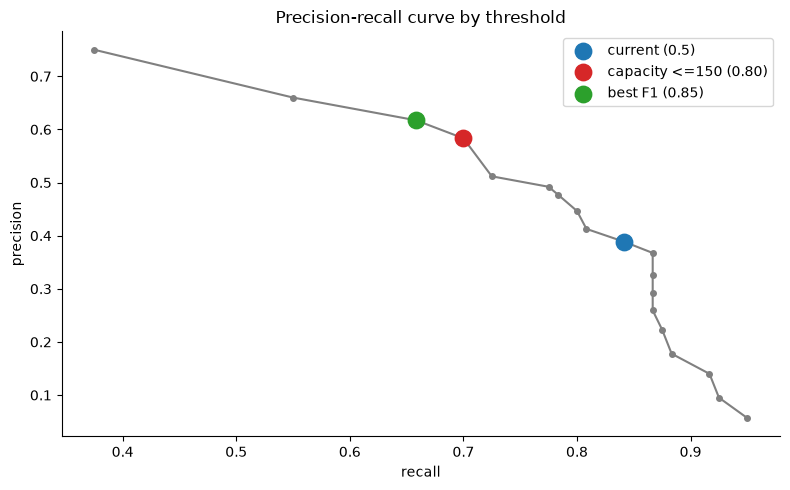

Recommendation: set threshold to 0.80 -> 144 alerts/month (within the 150 cap), recall 70.0%, precision 58.3%; today's 0.5 gives 260 alerts (precision 38.8%, recall 84.2%); best-F1 is 0.85 but needs 128 alerts.


In [5]:
rows = []
total_fraud = int(tx.is_fraud.sum())
# TODO 1: sweep thresholds
for t in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flagged_t = tx.detector_score >= t
    tp = int((flagged_t & (tx.is_fraud == 1)).sum())
    fp = int((flagged_t & (tx.is_fraud == 0)).sum())
    fn = total_fraud - tp
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / total_fraud
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    rows.append(dict(threshold=t, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=f1))

pr = pd.DataFrame(rows)
print(pr.round(3).to_string(index=False))

# TODO 2: capacity-constrained choice (<=150 alerts, max recall) and best-F1 choice
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3: precision-recall curve with the three marked choices
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", c="grey", ms=4)
for row, name, col in [(current, "current (0.5)", "tab:blue"),
                       (capacity_choice, f"capacity <=150 ({capacity_choice.threshold:.2f})", "tab:red"),
                       (best_f1, f"best F1 ({best_f1.threshold:.2f})", "tab:green")]:
    ax.scatter(row.recall, row.precision, s=140, c=col, zorder=3, label=name)
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall curve by threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4: recommendation
print(f"Recommendation: set threshold to {capacity_choice.threshold:.2f} -> {int(capacity_choice.alerts)} alerts/month "
      f"(within the 150 cap), recall {capacity_choice.recall:.1%}, precision {capacity_choice.precision:.1%}; "
      f"today's 0.5 gives {int(current.alerts)} alerts (precision {current.precision:.1%}, recall {current.recall:.1%}); "
      f"best-F1 is {best_f1.threshold:.2f} but needs {int(best_f1.alerts)} alerts.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

**Answer:** The Head of Fraud Ops should decide. A model can show the trade-offs, but review capacity and the relative cost of missed fraud versus unnecessary investigations are operational and risk decisions that require human judgement. Here the cap of 150 alerts picks 0.80 (144 alerts, recall 70%), while best F1 is at 0.85 (128 alerts, recall 66%), so the choice is really between a few more caught frauds and fewer false alarms. Visual analytics keeps the human in the loop (Slides 35–37) because people bring context, can steer the parameter while seeing the effect on the curve, and stay accountable for the decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: interactive scatter of flagged transactions
flagged = tx[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  color_discrete_map={"confirmed fraud": "crimson", "legitimate": "lightgrey"},
                  hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                              "distance_from_home_km": ":.1f", "detector_score": ":.3f",
                              "timestamp": False, "amount_inr": ":,.0f", "label": False},
                  title=f"Flagged transactions (score >= 0.3): {len(flagged)} cases")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2: drill-down sunburst city -> merchant category
sb = (tx.groupby(["city", "merchant_category"])
        .agg(n=("txn_id", "count"), fraud=("is_fraud", "sum")).reset_index())
sb["fraud_rate"] = sb.fraud / sb.n
fig2 = px.sunburst(sb, path=["city", "merchant_category"], values="n", color="fraud_rate",
                   color_continuous_scale="Reds", title="Drill-down: city -> category (size = transactions, colour = fraud rate)")
fig2.show()

In [7]:
import sys
!{sys.executable} -m pip install --upgrade nbformat ipython plotly

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

**Answer:** Tooltips reveal only one record at a time. Reviewing roughly 400 flagged cases this way requires repeated hovering and remembering earlier points, which is slow and makes a pattern like the Pune cluster difficult to spot (Slide 23). The overview views from this notebook fix that: the city × day heatmap (Task 1), the linked views (Task 2) and the sunburst drill-down give the big picture first, and the tooltip is then used only for details-on-demand on the few cases that matter.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: elevated fraud in Pune, days 18-20 (107 transactions in window)
Fraud rate inside window: 37.4% | outside: 1.48% | chi2=619.3, p=1.06e-136
(a) Pune on other days: 1.85%   (b) other cities on days 18-20: 0.44%   rest: 1.54%


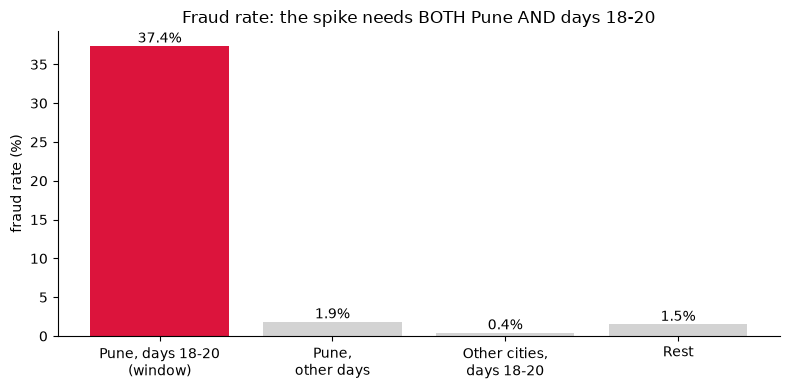

Verdict: SUPPORTED - the spike appears only where city AND days coincide (window 37.4% vs 1.85% / 0.44% in the counter-example groups; p=1.1e-136). Escalate the Pune 18-20 cluster; it is a localised burst, not a city-wide or month-wide problem.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis = a fraud ring in Pune on days 18-20 (the hot block in the Task 1 heatmap)
in_window = (tx.city == "Pune") & tx.day.between(18, 20)
print(f"Hypothesis: elevated fraud in Pune, days 18-20 ({int(in_window.sum())} transactions in window)")

# TODO 2: inside vs outside + chi-square
rate_in, rate_out = tx[in_window].is_fraud.mean(), tx[~in_window].is_fraud.mean()
chi2, p, dof, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"Fraud rate inside window: {rate_in:.1%} | outside: {rate_out:.2%} | chi2={chi2:.1f}, p={p:.2e}")

# TODO 3: counter-example searches
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = ~(in_window | same_city_other_days | other_cities_same_days)
rate_a = tx[same_city_other_days].is_fraud.mean()
rate_b = tx[other_cities_same_days].is_fraud.mean()
rate_rest = tx[rest].is_fraud.mean()
print(f"(a) Pune on other days: {rate_a:.2%}   (b) other cities on days 18-20: {rate_b:.2%}   rest: {rate_rest:.2%}")

# TODO 4: bar chart of the four groups
groups = ["Pune, days 18-20\n(window)", "Pune,\nother days", "Other cities,\ndays 18-20", "Rest"]
rates = [rate_in, rate_a, rate_b, rate_rest]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(groups, [r * 100 for r in rates], color=["crimson", "lightgrey", "lightgrey", "lightgrey"])
for b, r in zip(bars, rates):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{r:.1%}", ha="center", va="bottom")
ax.set(ylabel="fraud rate (%)", title="Fraud rate: the spike needs BOTH Pune AND days 18-20")
plt.tight_layout(); plt.show()

# TODO 5: verdict
verdict = ("SUPPORTED" if (p < 0.01 and rate_in > 5 * max(rate_a, rate_b)) else "NOT SUPPORTED")
print(f"Verdict: {verdict} - the spike appears only where city AND days coincide "
      f"(window {rate_in:.1%} vs {rate_a:.2%} / {rate_b:.2%} in the counter-example groups; p={p:.1e}). "
      f"Escalate the Pune 18-20 cluster; it is a localised burst, not a city-wide or month-wide problem.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

**Answer:** Counter-example (b), other cities on the same days, would have killed the hypothesis if it had come out high: it would have meant a system-wide event on days 18–20 (a data breach, a detector or data-feed problem, a seasonal spike) rather than a Pune ring. It came out low (0.44%), so that explanation is ruled out. Search (a), Pune on other days, would have pointed to a permanent Pune problem (e.g. a compromised terminal or merchant) if it had been high; it was normal (1.85%), so the spike really needs both Pune and the three-day window.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

**Final note:** Last month PayKart had 120 confirmed frauds in 5,520 transactions (2.2%), and a third of them (40) were a burst in Pune on days 18–20, where the fraud rate was 37.4% against 1.5% elsewhere (chi-square p about 1e-136), while Pune on other days and other cities on those days looked normal. I recommend raising the threshold from 0.5 to 0.80: it gives 144 alerts, inside the 150 cap (0.5 gives 260), with precision rising from 39% to 58% and recall of 70%; the best-F1 point of 0.85 (128 alerts, 66% recall) is an alternative, but this is a capacity-versus-risk trade-off, so the final choice should be made by you, with the model only supplying the precision–recall curve (human in the loop). The first interactive view to build is the overview city × day heatmap linked to the investigators' flagged-case scatter, because overview first (Slide 30) is what exposed the Pune burst, and details-on-demand tooltips then let them open individual cases. To improve next month's detector, add a feedback loop (Slide 51) in which investigators' confirmed labels and false-positive reasons are fed back to retrain the model, including features such as city-day bursts and the night-time far-from-home pattern.